# Origin–Destination Matrix (Flow Heatmap)

**Family:** Flow &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Flow:* Show the volume or intensity of movement between states, stages, or places.

## Design purpose

A grid with origins as rows, destinations as columns, and flow volume as cell shade. It shows every pairwise flow without clutter, so it scales to many more entities than a chord or Sankey.

## When to use

- Show many-to-many flows between 10–50 places (commuting, migration, referrals)
- Precise lookup of individual flows is needed
- Compare inflow and outflow patterns (rows vs. columns)

## Avoid when

- The goal is an intuitive, story-like overview for a lay audience (use a Sankey or flow map)
- Flows are sparse and few (use a network or chord)

## Alternatives

- Chord diagram
- Flow map
- Sankey diagram

## Design tips

- Use a one-hue sequential ramp; mask or gray out the diagonal if self-flows are meaningless
- Order rows and columns the same way, ideally by geography or cluster

## Example

Daily commuter flows (thousands) between 8 districts of a city.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import seaborn as sns

### Data

In [2]:
rng = np.random.default_rng(8)
districts = ["Central", "North", "East", "South", "West", "Harbor", "Hills", "Airport"]
attract = np.array([10, 3, 4, 3, 3, 5, 1, 4])        # job centers
pop = np.array([4, 8, 6, 9, 7, 3, 5, 2])
flows = np.outer(pop, attract) * rng.uniform(0.6, 1.4, (8, 8))
np.fill_diagonal(flows, 0)
od = pd.DataFrame(flows.round(0), index=districts, columns=districts)
od.iloc[:4, :4]

,Central,North,East,South
Central,0.0,17.0,14.0,15.0
North,55.0,0.0,25.0,19.0
East,48.0,19.0,0.0,20.0
South,55.0,20.0,33.0,0.0


### Plot

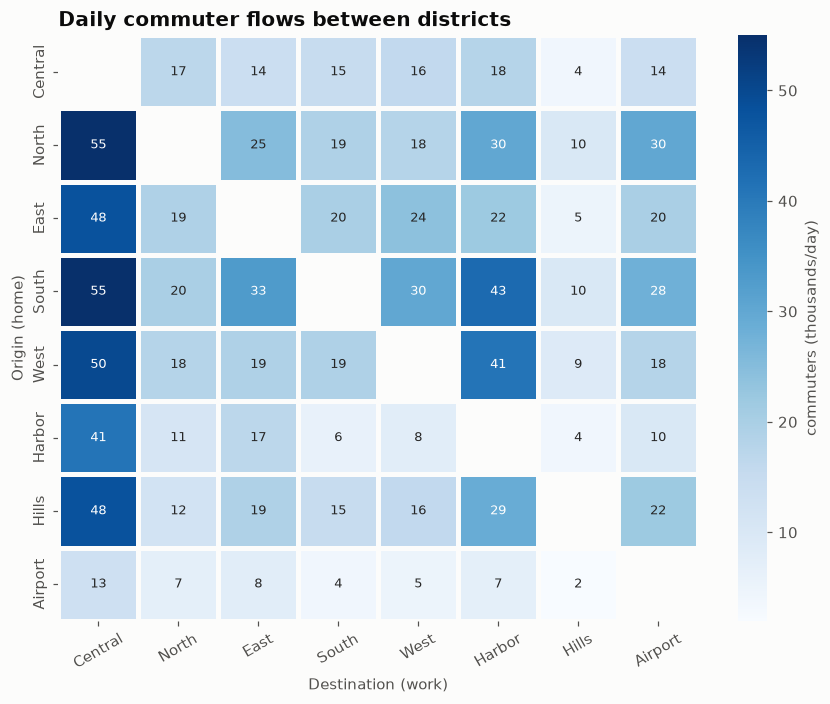

In [3]:
fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.eye(len(od), dtype=bool)
sns.heatmap(od, mask=mask, cmap=SEQ_CMAP, annot=True, fmt=".0f", linewidths=2,
            linecolor="#fcfcfb", cbar_kws=dict(label="commuters (thousands/day)"),
            annot_kws=dict(fontsize=8.5), ax=ax)
ax.set_xlabel("Destination (work)")
ax.set_ylabel("Origin (home)")
ax.set_title("Daily commuter flows between districts")
ax.tick_params(axis="x", rotation=30)
ax.grid(False)
fig.tight_layout()
plt.show()

## How to read it

Read across a row to see where residents of one district commute, and down a column to see where a district's workers come from. The dark Central column marks it as the main job hub.

---
Standalone script: [`origin_destination_matrix.py`](origin_destination_matrix.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)